In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

plt.rcParams['figure.figsize']=(10,6)
plt.rcParams['font.size']=11
sns.set_theme(style='whitegrid')

df=pd.read_csv('../data/AmesHousing.csv')

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(3)

Matplotlib is building the font cache; this may take a moment.


Dataset Shape: 2930 rows, 82 columns


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000


In [2]:
print("--- SalePrice Descriptive Statistics ---")
print(df['SalePrice'].describe().apply(lambda x: f"${x:,.2f}"))

price_skew=df['SalePrice'].skew()
price_kurt = df['SalePrice'].kurt()


print(f"\nSkewness: {price_skew:.2f} (Normal distribution = 0)")
print(f"Kurtosis: {price_kurt:.2f} (Measures heaviness of tails)")


--- SalePrice Descriptive Statistics ---
count      $2,930.00
mean     $180,796.06
std       $79,886.69
min       $12,789.00
25%      $129,500.00
50%      $160,000.00
75%      $213,500.00
max      $755,000.00
Name: SalePrice, dtype: str

Skewness: 1.74 (Normal distribution = 0)
Kurtosis: 5.12 (Measures heaviness of tails)


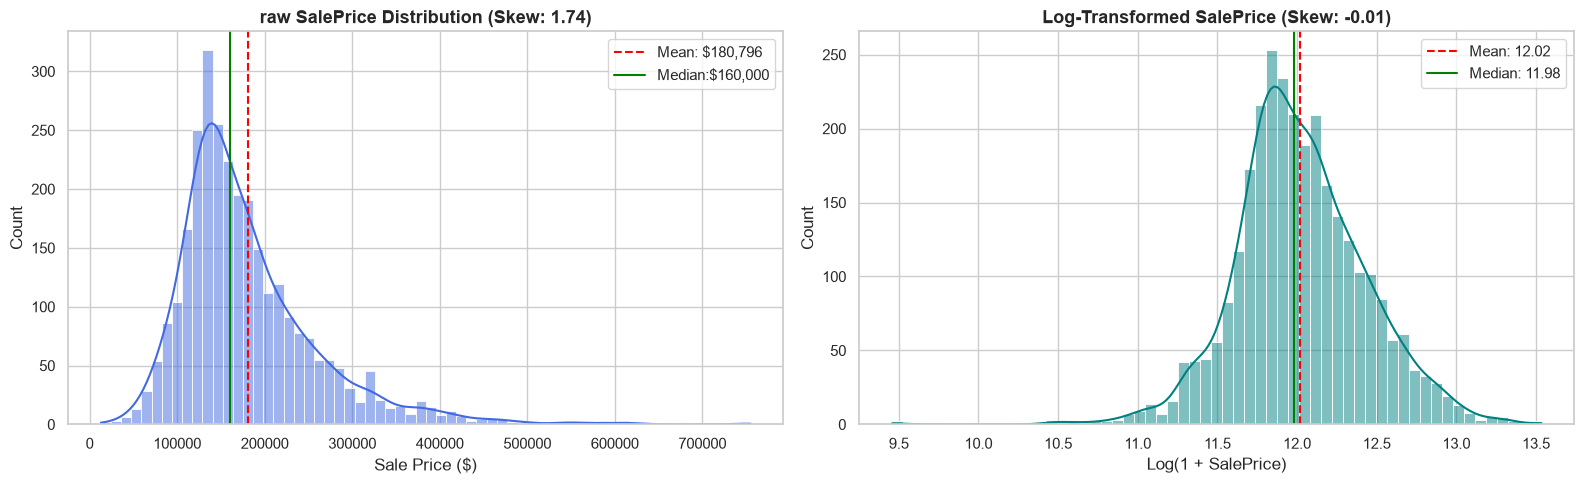

In [6]:
fig, axes=plt.subplots(1,2,figsize=(16, 5))

# Plot 1: Raw SalesPrice Distribution
sns.histplot(df['SalePrice'], kde=True, color='royalblue', ax=axes[0])
axes[0].axvline(df['SalePrice'].mean(), color='red', linestyle='--' , label=f"Mean: ${df['SalePrice'].mean():,.0f}")
axes[0].axvline(df['SalePrice'].median(), color='green', linestyle='-',label=f"Median:${df['SalePrice'].median():,.0f}")
axes[0].set_title(f"raw SalePrice Distribution (Skew: {price_skew:.2f})",fontsize=13,fontweight='bold')
axes[0].set_xlabel("Sale Price ($)")
axes[0].legend()


# Plot 2: Log-Transformed SalePrice Distribution
log_price = np.log1p(df['SalePrice'])
sns.histplot(log_price, kde=True,color='teal',ax=axes[1])
axes[1].axvline(log_price.mean(), color='red', linestyle='--', label=f"Mean: {log_price.mean():.2f}")
axes[1].axvline(log_price.median(), color='green', linestyle='-', label=f"Median: {log_price.median():.2f}")
axes[1].set_title(f"Log-Transformed SalePrice (Skew: {log_price.skew():.2f})", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Log(1 + SalePrice)")
axes[1].legend()

plt.tight_layout()
plt.show()


In [7]:
#1. Administrative ID columns to ignore during modeling
id_cols=['Order','PID']

# 2. Target column
target_col = 'SalePrice'

# 3. categorize remaining columns by date type
feature_cols=[c for c in df.columns if c not in id_cols + [target_col]]

numeric_cols=df[feature_cols].select_dtypes(include=[np.number]).columns.tolist()
categorical_cols=df[feature_cols].select_dtypes(include=['object']).columns.tolist()

print(f"Total Features Analyzed: {len(feature_cols)}")
print(f"-> Numeric Features:     {len(numeric_cols)}")
print(f"-> Categorical Features: {len(categorical_cols)}")
print(f"\nSample Numeric Columns:     {numeric_cols[:6]}")
print(f"Sample Categorical Columns: {categorical_cols[:6]}")


Total Features Analyzed: 79
-> Numeric Features:     36
-> Categorical Features: 43

Sample Numeric Columns:     ['MS SubClass', 'Lot Frontage', 'Lot Area', 'Overall Qual', 'Overall Cond', 'Year Built']
Sample Categorical Columns: ['MS Zoning', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities']


C:\Users\mindfire\AppData\Local\Temp\ipykernel_25624\163065082.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols=df[feature_cols].select_dtypes(include=['object']).columns.tolist()


In [9]:
# Calculate count and percentage of missing values per column

missing = df.isnull().sum()
missing=missing[missing >0].sort_values(ascending=False)
missing_pct=(missing/len(df)) * 100

missing_df=pd.DataFrame({
    'Missing Count': missing,
    'Missing Percentage (%)': missing_pct.round(2)
})

print(f"Total Columns with Missing Values: {len(missing_df)}")
print("\nTop 15 Columns with Highest Missing Values:")
missing_df.head(15)


Total Columns with Missing Values: 27

Top 15 Columns with Highest Missing Values:


,Missing Count,Missing Percentage (%)
Pool QC,2917,99.56
Misc Feature,2824,96.38
Alley,2732,93.24
Fence,2358,80.48
Mas Vnr Type,1775,60.58
Fireplace Qu,1422,48.53
Lot Frontage,490,16.72
Garage Qual,159,5.43
Garage Cond,159,5.43
Garage Yr Blt,159,5.43


C:\Users\mindfire\AppData\Local\Temp\ipykernel_25624\3146893801.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_df.head(15).index, y=missing_df.head(15)['Missing Percentage (%)'], palette='mako')


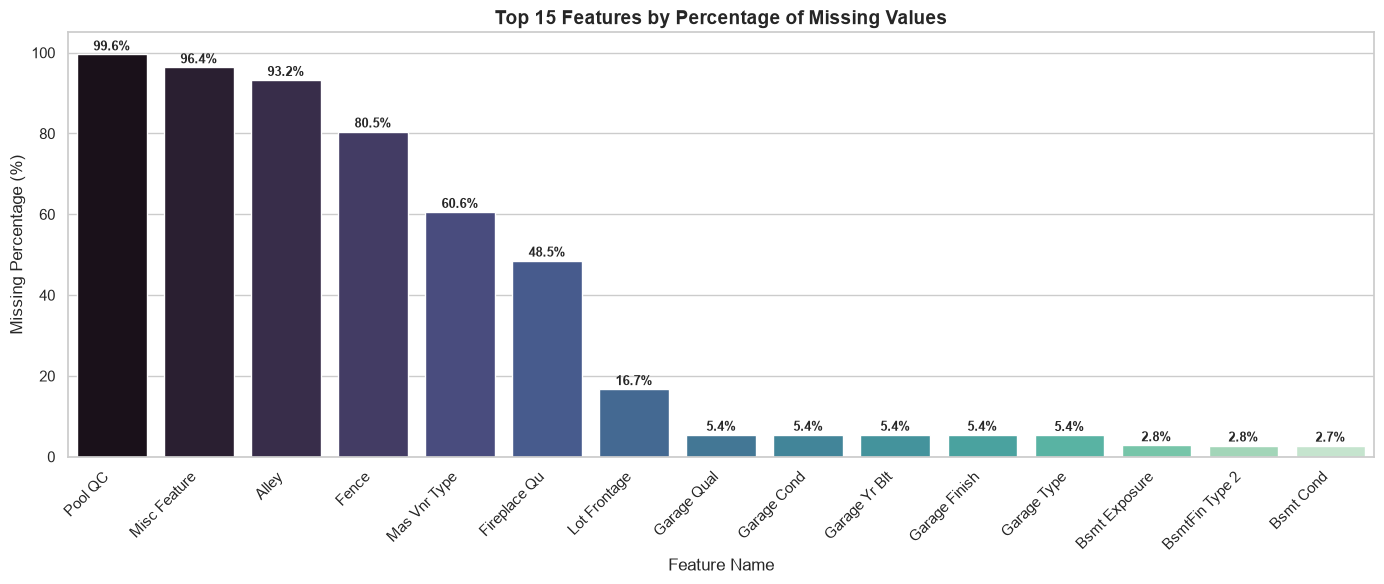

In [10]:
plt.figure(figsize=(14,6))
sns.barplot(x=missing_df.head(15).index, y=missing_df.head(15)['Missing Percentage (%)'], palette='mako')
plt.title("Top 15 Features by Percentage of Missing Values", fontsize=14, fontweight='bold')
plt.xlabel("Feature Name", fontsize=12)
plt.ylabel("Missing Percentage (%)", fontsize=12)
plt.xticks(rotation=45, ha='right')

# Add percentage text labels on top of each bar
for i, (col, row) in enumerate(missing_df.head(15).iterrows()):
    plt.text(i, row['Missing Percentage (%)'] + 1, f"{row['Missing Percentage (%)']:.1f}%", 
             ha='center', fontsize=9, fontweight='bold')
plt.ylim(0, 105)
plt.tight_layout()
plt.show()


In [11]:
# Compute correlation matrix for numeric features against SalePrice
num_features_with_target = numeric_cols + [target_col]
corr_matrix=df[num_features_with_target].corr()

# Extract top 10 features most correlated with SalePrice 
top_corr_features = corr_matrix[target_col].sort_values(ascending=False).iloc[1:11]

print("=== Top 10 Positively Correlated Features with SalePrice ===")
for rank, (feat, val) in enumerate(top_corr_features.items(), start=1):
    print(f"{rank:2d}. {feat:<18} : r = {val:+.3f}")

=== Top 10 Positively Correlated Features with SalePrice ===
 1. Overall Qual       : r = +0.799
 2. Gr Liv Area        : r = +0.707
 3. Garage Cars        : r = +0.648
 4. Garage Area        : r = +0.640
 5. Total Bsmt SF      : r = +0.632
 6. 1st Flr SF         : r = +0.622
 7. Year Built         : r = +0.558
 8. Full Bath          : r = +0.546
 9. Year Remod/Add     : r = +0.533
10. Garage Yr Blt      : r = +0.527


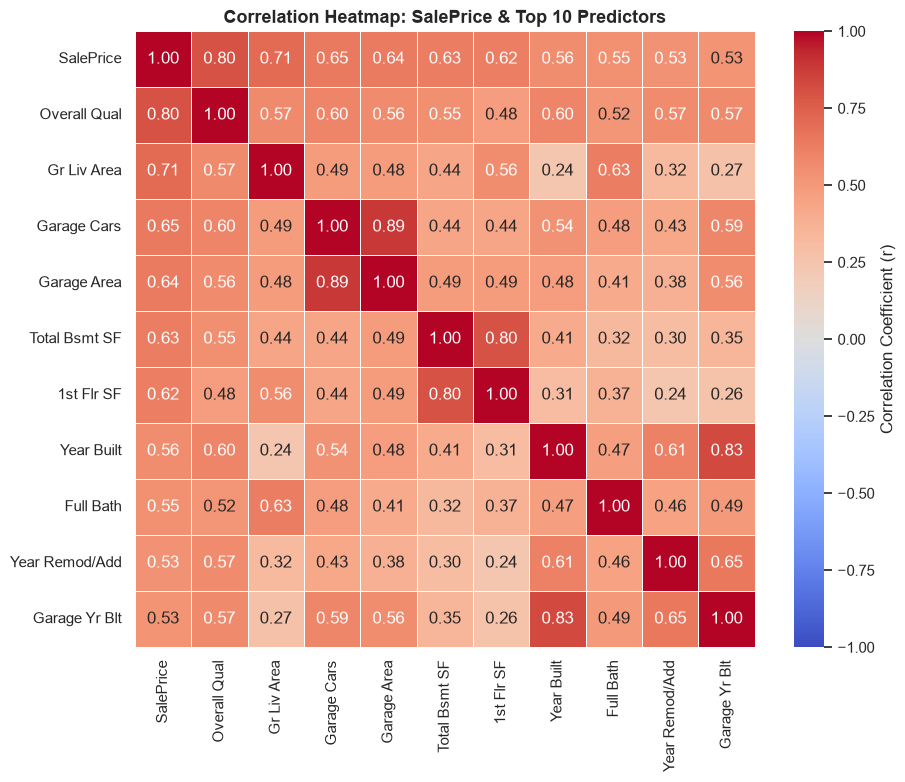

In [13]:
# Select top 10 features plus the target for a focused heatmap
top_cols = [target_col] + top_corr_features.index.tolist()
sub_corr = df[top_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(sub_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, 
            linewidths=0.5, cbar_kws={'label': 'Correlation Coefficient (r)'})
plt.title("Correlation Heatmap: SalePrice & Top 10 Predictors", fontsize=13, fontweight='bold')
plt.show()


C:\Users\mindfire\AppData\Local\Temp\ipykernel_25624\1021701664.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Overall Qual', y='SalePrice', ax=axes[1], palette='Blues')


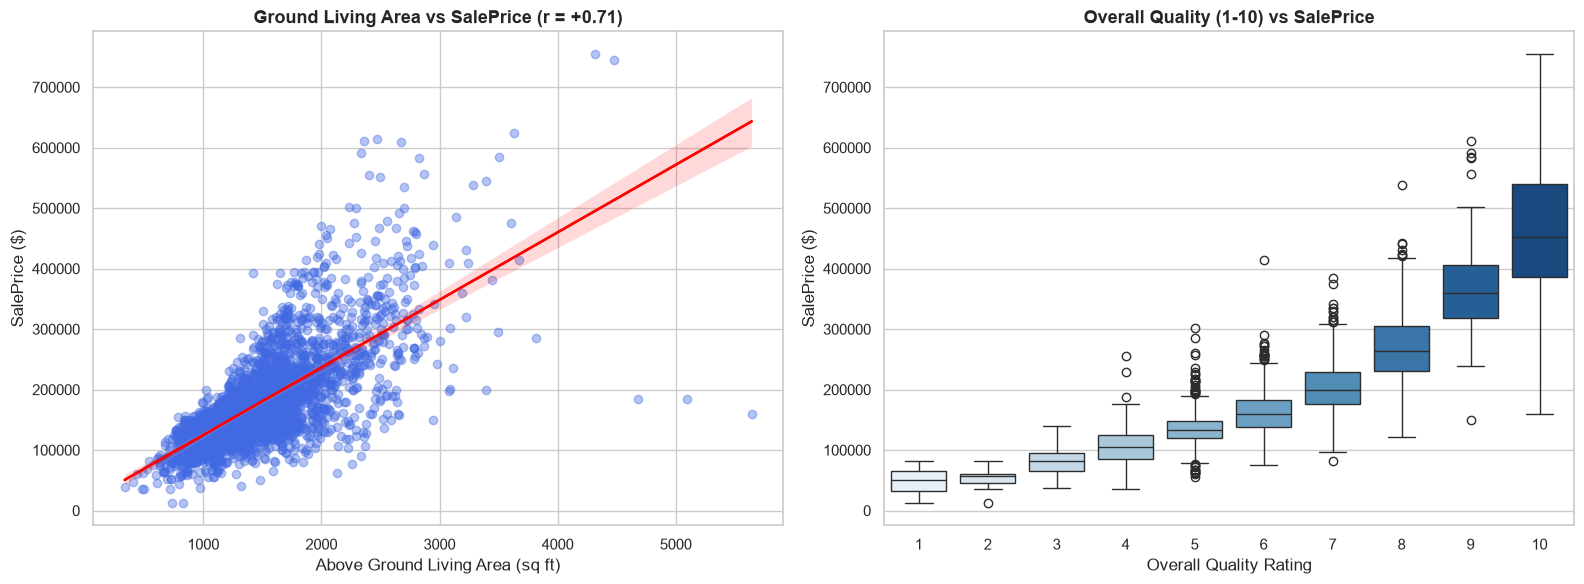

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Living Area vs SalePrice (Scatter with trendline)
sns.regplot(data=df, x='Gr Liv Area', y='SalePrice', ax=axes[0],
            scatter_kws={'alpha': 0.4, 'color': 'royalblue'}, line_kws={'color': 'red', 'linewidth': 2})
axes[0].set_title("Ground Living Area vs SalePrice (r = +0.71)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Above Ground Living Area (sq ft)")
axes[0].set_ylabel("SalePrice ($)")

# Plot 2: Overall Quality vs SalePrice (Boxplot showing price distribution per quality rating)
sns.boxplot(data=df, x='Overall Qual', y='SalePrice', ax=axes[1], palette='Blues')
axes[1].set_title("Overall Quality (1-10) vs SalePrice", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Overall Quality Rating")
axes[1].set_ylabel("SalePrice ($)")

plt.tight_layout()
plt.show()


C:\Users\mindfire\AppData\Local\Temp\ipykernel_25624\3255341018.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Neighborhood', y='SalePrice', order=neighborhood_order, palette='crest')


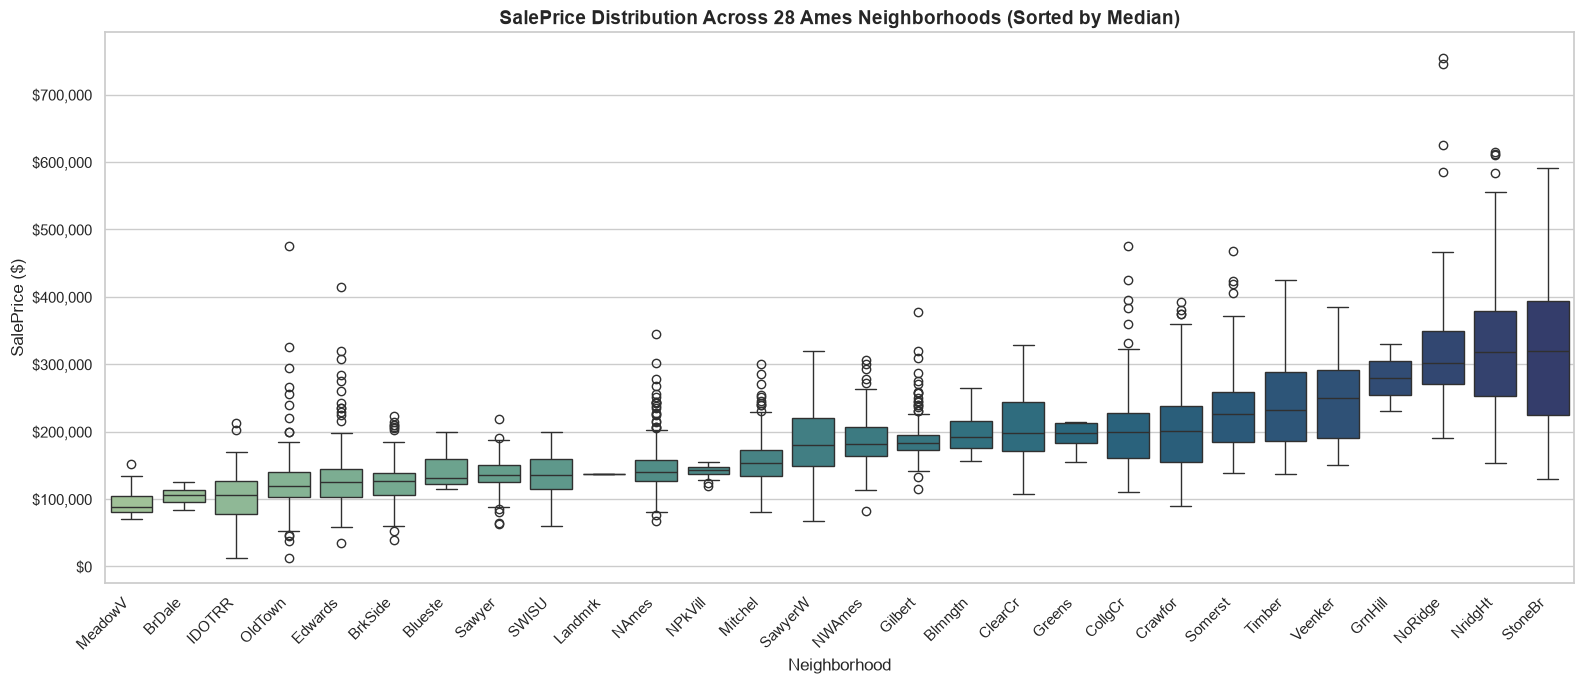

In [15]:
# Compute median price and count per neighborhood, sorted ascending
neighborhood_order = df.groupby('Neighborhood')['SalePrice'].median().sort_values().index

plt.figure(figsize=(16, 7))
sns.boxplot(data=df, x='Neighborhood', y='SalePrice', order=neighborhood_order, palette='crest')
plt.xticks(rotation=45, ha='right', fontsize=11)
plt.title("SalePrice Distribution Across 28 Ames Neighborhoods (Sorted by Median)", fontsize=14, fontweight='bold')
plt.xlabel("Neighborhood", fontsize=12)
plt.ylabel("SalePrice ($)", fontsize=12)

# Format y-axis with dollar commas
plt.gca().yaxis.set_major_formatter('${x:,.0f}')
plt.tight_layout()
plt.show()


In [16]:
# Filter houses with more than 4,000 sq ft living area
large_houses = df[df['Gr Liv Area'] > 4000][['Order', 'Gr Liv Area', 'Overall Qual', 'Sale Condition', 'SalePrice']]
print("=== Houses with Living Area > 4,000 sq ft ===")
large_houses


=== Houses with Living Area > 4,000 sq ft ===


,Order,Gr Liv Area,Overall Qual,Sale Condition,SalePrice
1498,1499,5642,10,Partial,160000
1760,1761,4476,10,Abnorml,745000
1767,1768,4316,10,Normal,755000
2180,2181,5095,10,Partial,183850
2181,2182,4676,10,Partial,184750


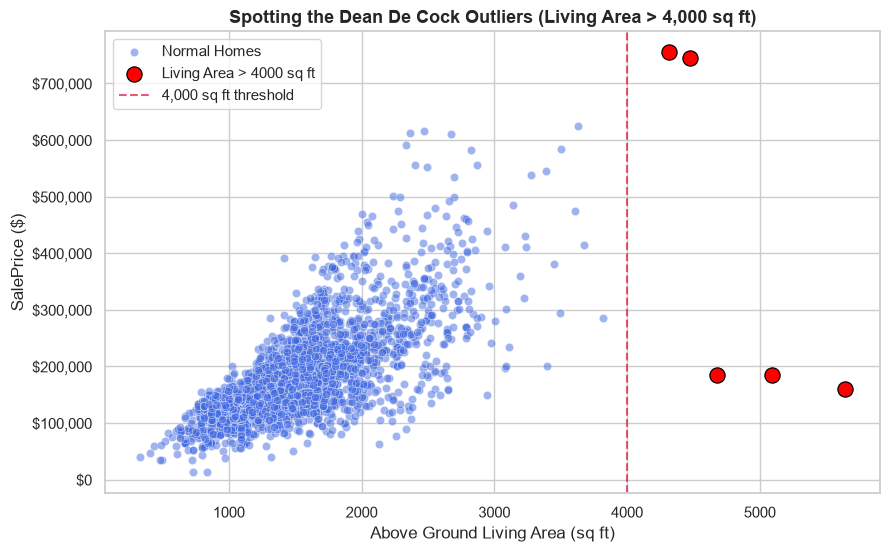

In [17]:
plt.figure(figsize=(10, 6))
# Plot all normal houses
sns.scatterplot(data=df[df['Gr Liv Area'] <= 4000], x='Gr Liv Area', y='SalePrice', 
                alpha=0.5, color='royalblue', label='Normal Homes')

# Highlight the > 4000 sq ft homes
sns.scatterplot(data=df[df['Gr Liv Area'] > 4000], x='Gr Liv Area', y='SalePrice', 
                color='red', s=120, edgecolor='black', label='Living Area > 4000 sq ft')

plt.title("Spotting the Dean De Cock Outliers (Living Area > 4,000 sq ft)", fontsize=13, fontweight='bold')
plt.xlabel("Above Ground Living Area (sq ft)")
plt.ylabel("SalePrice ($)")
plt.gca().yaxis.set_major_formatter('${x:,.0f}')
plt.axvline(4000, color='crimson', linestyle='--', alpha=0.7, label='4,000 sq ft threshold')
plt.legend()
plt.show()


### Summary of Findings from Milestone 1 (EDA):

1. **Target Variable (`SalePrice`):**
   - Heavily right-skewed (+1.74 skew). 
   - Transformed with `np.log1p(SalePrice)` to achieve an almost perfect normal bell curve (-0.01 skew).

2. **The "NA" Trap:**
   - Most missing values (`Pool QC`, `Alley`, `Fence`, `Fireplace Qu`, `Garage Qual`, `Bsmt Qual`) are **Structural NAs** representing "No Amenity", not missing data.
   - Genuine missing data is limited (`Lot Frontage` with 490 missing values).

3. **Top Positive Signals:**
   - `Overall Qual` ($r = 0.80$) and `Gr Liv Area` ($r = 0.71$) dominate price predictions.

4. **Multicollinearity:**
   - `Garage Cars` & `Garage Area` ($r = 0.89$), `Total Bsmt SF` & `1st Flr SF` ($r = 0.80$) are redundant. Regularization (Ridge/LASSO) will be crucial.

5. **Location Matters:**
   - 28 neighborhoods show median prices ranging from $88k (`MeadowV`) to $319k (`StoneBr`). One-Hot Encoding is required.

6. **Outliers:**
   - Two extreme partial sales with living area > 4,000 sq ft sold for < $200k. They must be removed before training linear models.
